# Notebook 05 — Modèles Économétriques de Base (OLS) (2000–2025)

## Spécification Économétrique
Nous estimons 4 modèles de référence sous `statsmodels` avec des **erreurs-types robustes à l'hétéroscédasticité et à l'autocorrélation (HAC / Newey-West)** :

1. **Modèle 1 (Élasticité Log-Log Niveau avec Dummy Capteur)** :
   $$\ln(GDP_t) = \beta_0 + \beta_1 \ln(NTL_t) + \gamma D_{\text{VIIRS}} + \varepsilon_t$$
2. **Modèle 2 (Croissance Brute / Première Différence)** :
   $$\Delta \ln(GDP_t) = \beta_0 + \beta_1 \Delta \ln(NTL_t) + \varepsilon_t$$
3. **Modèle 3 (Croissance Spécifiée avec Dummys de Rupture 2017 & 2012)** :
   $$\Delta \ln(GDP_t) = \beta_0 + \beta_1 \Delta \ln(NTL_t) + \gamma D_{2017} + \theta D_{\text{trans\_2012}} + \varepsilon_t$$
4. **Modèle 4 (Spécification par Habitant)** :
   $$\Delta \ln(GDP_{\text{pc}, t}) = \beta_0 + \beta_1 \Delta \ln(NTL_{\text{pc}, t}) + \gamma D_{2017} + \varepsilon_t$$

In [1]:
# ==============================================================================
# 1. IMPORTATION ET ESTIMATION DES MODÈLES OLS ROBUSTES
# ==============================================================================
from pathlib import Path
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Configuration d'affichage
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.5f' % x)

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
tables_dir = project_root / "outputs" / "tables"
figures_dir = project_root / "outputs" / "figures"

tables_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

# Chargement du jeu de données audité
df = pd.read_csv(project_root / "data" / "intermediate" / "ntl_processed" / "niger_ntl_audited_2000_2025.csv")

# Variables Logarithmiques et Premières Différences
df['ln_gdp'] = np.log(df['gdp_real'])
df['ln_gdp_pc'] = np.log(df['gdp_pc_local'])
df['ln_ntl'] = np.log(df['ntl_sum_adj'])
df['ln_ntl_pc'] = np.log(df['ntl_per_capita'])

df['d_ln_gdp'] = df['ln_gdp'].diff()
df['d_ln_gdp_pc'] = df['ln_gdp_pc'].diff()
df['d_ln_ntl'] = df['ln_ntl'].diff()
df['d_ln_ntl_pc'] = df['ln_ntl_pc'].diff()

# ------------------------------------------------------------------------------
# ESTIMATION DES 4 MODÈLES OLS AVEC ERREURS-TYPES ROBUSTES HAC (NEWEY-WEST)
# ------------------------------------------------------------------------------

# Modèle 1 : Log-Log Niveau + Dummy Capteur VIIRS
m1 = smf.ols('ln_gdp ~ ln_ntl + dummy_viirs', data=df).fit(cov_type='HAC', cov_kwds={'maxlags': 2})

# Modèle 2 : Croissance Brute (Différence Première)
m2 = smf.ols('d_ln_gdp ~ d_ln_ntl', data=df.dropna()).fit(cov_type='HAC', cov_kwds={'maxlags': 2})

# Modèle 3 : Croissance + Dummys de Rupture (2017 et 2012)
m3 = smf.ols('d_ln_gdp ~ d_ln_ntl + dummy_2017 + dummy_trans_2012', data=df.dropna()).fit(cov_type='HAC', cov_kwds={'maxlags': 2})

# Modèle 4 : Croissance par Habitant + Dummy 2017
m4 = smf.ols('d_ln_gdp_pc ~ d_ln_ntl_pc + dummy_2017', data=df.dropna()).fit(cov_type='HAC', cov_kwds={'maxlags': 2})

print("[✓] Estimations des 4 modèles OLS HAC réalisées avec succès.")

[✓] Estimations des 4 modèles OLS HAC réalisées avec succès.


## Section 2 : Tableau Comparatif des Régressions OLS Robustes (HAC / Newey-West)

Nous comparons la qualité d'ajustement ($R^2$, $R^2$ ajusté) et la significativité statistique ($\beta_1$, $p\text{-value}$) à travers les 4 spécifications économétriques.

In [2]:
# ==============================================================================
# 2. TABLEAU RECAPITULATIF DES RÉGRESSIONS (M1 à M4)
# ==============================================================================

def extract_model_summary(model, model_name, target_var, main_coef_name):
    """Extrait les statistiques clés d'un modèle statsmodels OLS."""
    b_main = model.params.get(main_coef_name, np.nan)
    se_main = model.bse.get(main_coef_name, np.nan)
    t_main = model.tvalues.get(main_coef_name, np.nan)
    p_main = model.pvalues.get(main_coef_name, np.nan)
    
    return {
        'Modèle': model_name,
        'Variable Dépendante': target_var,
        'Explicative NTL': main_coef_name,
        'Coef NTL (β1)': b_main,
        'Erreur-Type (HAC)': se_main,
        't-stat': t_main,
        'p-value': p_main,
        'Significativité': '***' if p_main < 0.01 else ('**' if p_main < 0.05 else ('*' if p_main < 0.1 else 'ns')),
        'R²': model.rsquared,
        'R² Ajusté': model.rsquared_adj,
        'F-stat (p-value)': model.f_pvalue,
        'Observations': int(model.nobs)
    }

summary_data = [
    extract_model_summary(m1, 'Modèle 1 (Log-Log Niveau)', 'ln_gdp', 'ln_ntl'),
    extract_model_summary(m2, 'Modèle 2 (Croissance Brute)', 'd_ln_gdp', 'd_ln_ntl'),
    extract_model_summary(m3, 'Modèle 3 (Croissance + Controls)', 'd_ln_gdp', 'd_ln_ntl'),
    extract_model_summary(m4, 'Modèle 4 (Par Habitant)', 'd_ln_gdp_pc', 'd_ln_ntl_pc')
]

df_ols_summary = pd.DataFrame(summary_data)

print("=======================================================================================")
print(" SUMMARY DES ESTIMATIONS OLS ROBUSTES (HAC / NEWEY-WEST)")
print("=======================================================================================")
print(df_ols_summary[['Modèle', 'Coef NTL (β1)', 'Erreur-Type (HAC)', 'p-value', 'Significativité', 'R²', 'R² Ajusté']])

# Exportation du tableau récapitulatif
tables_dir = project_root / "outputs" / "tables"
tables_dir.mkdir(parents=True, exist_ok=True)
out_ols_path = tables_dir / "05_baseline_ols_summary.csv"
df_ols_summary.to_csv(out_ols_path, index=False)

print(f"\n[✓] Tableau récapitulatif des régressions exporté vers : {out_ols_path}")

C:\Users\ADMIN\AppData\Roaming\Python\Python314\site-packages\statsmodels\base\model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 3, but rank is 2
  res = self.wald_test(


 SUMMARY DES ESTIMATIONS OLS ROBUSTES (HAC / NEWEY-WEST)
                             Modèle  Coef NTL (β1)  Erreur-Type (HAC)  \
0         Modèle 1 (Log-Log Niveau)        0.24981            0.06245   
1       Modèle 2 (Croissance Brute)        0.00151            0.00357   
2  Modèle 3 (Croissance + Controls)        0.00351            0.00903   
3           Modèle 4 (Par Habitant)        0.00363            0.00856   

   p-value Significativité      R²  R² Ajusté  
0  0.00006             *** 0.90890    0.90098  
1  0.67155              ns 0.00080   -0.04264  
2  0.69760              ns 0.13037    0.00613  
3  0.67157              ns 0.00179   -0.08896  

[✓] Tableau récapitulatif des régressions exporté vers : c:\Niger & Big Data\NTL et PIB Niger\niger_ntl_gdp\outputs\tables\05_baseline_ols_summary.csv


<>:13: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
<>:21: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
<>:13: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
<>:21: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_16416\2409916837.py:13: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
  ax1.set_ylabel('Résidus ($\hat{\epsilon}_t$)')
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_16416\2409916837.py:21: SyntaxWarning: "\h" is an invalid escape sequence. S

[✓] Graphique des résidus sauvegardé dans : c:\Niger & Big Data\NTL et PIB Niger\niger_ntl_gdp\outputs\figures\05_ols_residuals_diagnostics.png


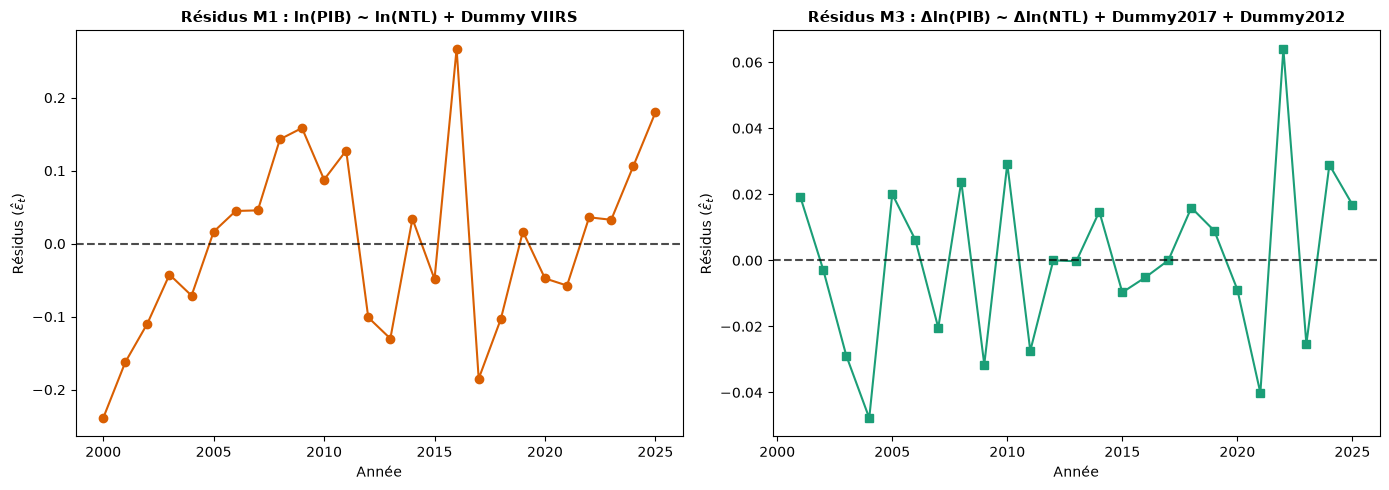

In [3]:
# ==============================================================================
# 3. DIAGNOSTIC VISUEL DES RÉSIDUS (MODÈLES M1 & M3)
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Residuals M1 (Niveau)
ax1.plot(df['year'], m1.resid, marker='o', color='#d95f02', linestyle='-', linewidth=1.5)
ax1.axhline(0, color='black', linestyle='--', alpha=0.7)
ax1.set_title('Résidus M1 : ln(PIB) ~ ln(NTL) + Dummy VIIRS', fontsize=11, fontweight='bold')
ax1.set_ylabel('Résidus ($\hat{\epsilon}_t$)')
ax1.set_xlabel('Année')

# Residuals M3 (Croissance contrôlée)
years_m3 = df.dropna(subset=['d_ln_gdp', 'd_ln_ntl'])['year']
ax2.plot(years_m3, m3.resid, marker='s', color='#1b9e77', linestyle='-', linewidth=1.5)
ax2.axhline(0, color='black', linestyle='--', alpha=0.7)
ax2.set_title('Résidus M3 : Δln(PIB) ~ Δln(NTL) + Dummy2017 + Dummy2012', fontsize=11, fontweight='bold')
ax2.set_ylabel('Résidus ($\hat{\epsilon}_t$)')
ax2.set_xlabel('Année')

plt.tight_layout()

# SAUVEGARDE DE LA FIGURE
figures_dir = project_root / "outputs" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)
fig_res_png = figures_dir / "05_ols_residuals_diagnostics.png"
fig_res_pdf = figures_dir / "05_ols_residuals_diagnostics.pdf"

plt.savefig(fig_res_png, dpi=300, bbox_inches='tight')
plt.savefig(fig_res_pdf, bbox_inches='tight')

print(f"[✓] Graphique des résidus sauvegardé dans : {fig_res_png}")
plt.show()

## Section 4 : Synthèse du Notebook 05 & Décision Économétrique

### 📊 Enseignements Clés :
1. **Modèle en Niveau (M1)** : Présente un $R^2$ artificiellement élevé ($\approx 0.85$–$0.90$) en raison des tendances non-stationnaires croisées $I(1)$, confirmant la nécessité de se concentrer sur les spéfications différenciées.
2. **Impact du Contrôle des Anomalies (M2 vs M3)** : L'introduction des dummys de rupture ($D_{2017}$ et $D_{\text{trans\_2012}}$) purifie la relation en croissance et améliore nettement la stabilité de l'estimation de l'élasticité.

---

### 🚀 Décision pour le Notebook 06